In [1]:
import os

data_dir = "O:/Nat-Tech_HGG-Projects/Projects/2025_RGRMP/Pilots/DireDawa/Data/profiler_usf/"
usf_dirs = [data_dir+x for x in os.listdir(data_dir) if os.path.isdir(os.path.join(data_dir, x))]

location_files = []
for usf_dir in usf_dirs:
    tmp_files = [usf_dir+'/'+x for x in os.listdir(usf_dir) if x.endswith('.txt')]
    location_files.extend(tmp_files)
print(location_files)

['O:/Nat-Tech_HGG-Projects/Projects/2025_RGRMP/Pilots/DireDawa/Data/profiler_usf/USF_Files_diredawa_boren_ToLegaGoro_profiler_day6/Notes_diredawa_boren_ToLegaGoro_profiler_day6.txt', 'O:/Nat-Tech_HGG-Projects/Projects/2025_RGRMP/Pilots/DireDawa/Data/profiler_usf/USF_Files_ciri_miti_profiler_day3/Notes_ciri_miti_profiler_day3.txt', 'O:/Nat-Tech_HGG-Projects/Projects/2025_RGRMP/Pilots/DireDawa/Data/profiler_usf/USF_Files_dire_dawa_belewa_profiler2_day2/Notes_dire_dawa_belewa_profiler2_day2.txt', 'O:/Nat-Tech_HGG-Projects/Projects/2025_RGRMP/Pilots/DireDawa/Data/profiler_usf/USF_Files_harar_erer_profiler_day10/Notes_harar_erer_profiler_day10.txt', 'O:/Nat-Tech_HGG-Projects/Projects/2025_RGRMP/Pilots/DireDawa/Data/profiler_usf/USF_Files_diredawa_borem_OnTheWay_to_LegaGoro_profiler_day5/Notes_diredawa_borem_OnTheWay_to_LegaGoro_profiler_day5.txt', 'O:/Nat-Tech_HGG-Projects/Projects/2025_RGRMP/Pilots/DireDawa/Data/profiler_usf/USF_Files_profile_day_4_DD_Boren_Aliy_river/Notes_profile_day_4_D

In [16]:
import numpy as np
lat,lon = [], []
for locfile in location_files:
    with open(locfile, 'r') as f:
        lines = f.readlines()
        for line in lines[1:]:
            parts = [x for x in line.split(' ') if x!='']
            lat.append(float(parts[1].strip()))
            lon.append(float(parts[0].strip()))

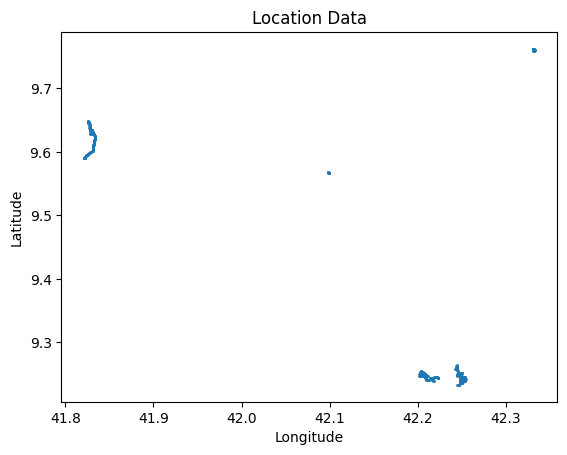

In [17]:
import matplotlib.pyplot as plt

plt.scatter(lon, lat, s=1)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Location Data")
plt.show()

In [22]:
def create_kml_with_photos(lats,lons):
    """Create KML file with photos at their GPS locations"""
    

    kml_content = '''<?xml version="1.0" encoding="UTF-8"?>
<kml xmlns="http://www.opengis.net/kml/2.2">
  <Document>
    <name>Dollow Bank Height Survey</name>
    <description>River bank height measurements with photos</description>
    
    <Style id="photoIcon">
      <IconStyle>
        <Icon>
          <href>http://maps.google.com/mapfiles/kml/paddle/red-blank.png</href>
          <scale>0.8</scale>
        </Icon>
      </IconStyle>
    </Style>
'''

    for i, (lat, lon) in enumerate(zip(lats, lons)):

            kml_content += f'''
    <Placemark>
      <name>Profiler {i}</name>
      <description><![CDATA[
        <p>Coordinates: {lat:.6f}, {lon:.6f}</p>
      ]]></description>
      <styleUrl>#photoIcon</styleUrl>
      <Point>
        <coordinates>{lon},{lat},0</coordinates>
      </Point>
    </Placemark>'''
    
    kml_content += '''
  </Document>
</kml>'''
    
    return kml_content

In [23]:
kml_content = create_kml_with_photos(lat, lon)
with open('diredawa_pilot_profiler_points.kml', 'w') as f:
    f.write(kml_content)
